### Question: Identifying Key Vocabulary for Digital Book Analysis

A digital publishing company is developing a **text-analysis system** to understand which words are most prominent in classic books. As a first step, the company wants to analyse *Alice's Adventures in Wonderland* and identify frequently used vocabulary and patterns in word usage.

The complete text of the book is stored in a file named `alice.txt`.

Write a program that reads the file and performs the following analysis. The analysis should treat words such as `Alice` and `alice` as the same word and should ignore punctuation.

Your program should:

1. Count the number of occurrences of every word in the book.

2. Identify the **50 most frequently occurring words** and display each word along with its frequency.

4. Analyse how **word length is related to word usage** by determining the total number of occurrences corresponding to each word length.

5. Display the word-length analysis, showing each word length along with its corresponding total number of occurrences.

The `alice.txt` file will be provided with the assignment.

In [3]:
import string
import pandas as pd

def analyze_text(text):
    text = text.lower()
    text = text.translate(str.maketrans('', '', string.punctuation))
    words = text.split()

    word_count = {}
    for word in words:
        word_count[word] = word_count.get(word, 0) + 1

    length_count = {}
    for word, count in word_count.items():
        length = len(word)
        length_count[length] = length_count.get(length, 0) + count

    top_words = sorted(
        word_count.items(),
        key=lambda x: x[1],
        reverse=True
    )[:50]

    return word_count, top_words, length_count

In [6]:
from hamcrest import assert_that, equal_to

para = """
Alice was beginning to get very tired of sitting by her sister on the bank,
and of having nothing to do: once or twice she had peeped into the book her
sister was reading, but it had no pictures or conversations in it, 'and what
is the use of a book,' thought Alice 'without pictures or conversations?'
"""

word_count, top_words, length_count = analyze_text(para)

# Check total number of words
assert_that(sum(word_count.values()), equal_to(57))

# Check case conversion
assert_that(word_count["alice"], equal_to(2))

# Check important word frequencies
assert_that(word_count["of"], equal_to(3))
assert_that(word_count["the"], equal_to(3))
assert_that(word_count["or"], equal_to(3))
assert_that(word_count["book"], equal_to(2))
assert_that(word_count["conversations"], equal_to(2))

# Check punctuation removal
assert_that("book" in word_count, equal_to(True))
assert_that("book," in word_count, equal_to(False))

# Check top words
assert_that(
    top_words[:5],
    equal_to([
        ("of", 3),
        ("the", 3),
        ("or", 3),
        ("alice", 2),
        ("was", 2)
    ])
)

# Check word-length analysis
expected_length_count = {
    1: 1,
    2: 16,
    3: 15,
    4: 7,
    5: 4,
    6: 4,
    7: 5,
    8: 2,
    9: 1,
    13: 2
}

assert_that(length_count, equal_to(expected_length_count))

# Check number of unique words
assert_that(len(word_count), equal_to(40))

print("All tests passed!")

All tests passed!


### Question: Spam Message Detection

A mobile service provider wants to automatically identify whether an incoming text message is **spam** or **not spam**. The following labelled messages are available:

```python
messages = [
    "Congratulations you have won a free prize",
    "Win a free mobile phone now",
    "Claim your reward by clicking the link",
    "You have won a cash prize",
    "Meeting is scheduled for tomorrow at 10 AM",
    "Please submit the assignment by Friday",
    "Can you send me the project report",
    "The lecture will begin at 9 AM"
]

labels = [
    "spam",
    "spam",
    "spam",
    "spam",
    "ham",
    "ham",
    "ham",
    "ham"
]
```


The provider wants to build a simple rule-based spam detector using word frequencies.

Perform the following:

1. Convert all messages to lowercase and remove punctuation.
2. Count the frequency of every word separately in the **spam** and **ham** messages.
3. Create a Pandas DataFrame containing the columns:
` word | spam_frequency | ham_frequency `
4. Identify the words that occur more frequently in spam messages than in ham messages.
5. Given the following new message:

```python
new_message = "Congratulations you have won a free reward"
```
5. Process the new message in the same way and calculate its total spam word frequency and ham word frequency.
6. Classify the new message as `spam` if its spam word frequency is greater than its ham word frequency; otherwise classify it as `ham`.
7. Display the predicted class of the new message.


In [7]:
import string
import pandas as pd

def spam_detector(messages, labels, new_message):
    spam_freq = {}
    ham_freq = {}

    for message, label in zip(messages, labels):
        message = message.lower().translate(
            str.maketrans('', '', string.punctuation)
        )

        for word in message.split():
            freq = spam_freq if label == "spam" else ham_freq
            freq[word] = freq.get(word, 0) + 1

    words = sorted(set(spam_freq) | set(ham_freq))

    df = pd.DataFrame({
        'word': words,
        'spam_frequency': [spam_freq.get(word, 0) for word in words],
        'ham_frequency': [ham_freq.get(word, 0) for word in words]
    })

    new_message = new_message.lower().translate(
        str.maketrans('', '', string.punctuation)
    )

    spam_score = sum(spam_freq.get(word, 0) for word in new_message.split())
    ham_score = sum(ham_freq.get(word, 0) for word in new_message.split())

    prediction = "spam" if spam_score > ham_score else "ham"

    return df, spam_score, ham_score, prediction

In [8]:
messages = [
    "Congratulations you have won a free prize",
    "Win a free mobile phone now",
    "Claim your reward by clicking the link",
    "You have won a cash prize",
    "Meeting is scheduled for tomorrow at 10 AM",
    "Please submit the assignment by Friday",
    "Can you send me the project report",
    "The lecture will begin at 9 AM"
]

labels = [
    "spam", "spam", "spam", "spam",
    "ham", "ham", "ham", "ham"
]

new_message = "Congratulations you have won a free reward"

df, spam_score, ham_score, prediction = spam_detector(
    messages, labels, new_message
)

print(df)
print("Spam score:", spam_score)
print("Ham score:", ham_score)
print("Prediction:", prediction)

               word  spam_frequency  ham_frequency
0                10               0              1
1                 9               0              1
2                 a               3              0
3                am               0              2
4        assignment               0              1
5                at               0              2
6             begin               0              1
7                by               1              1
8               can               0              1
9              cash               1              0
10            claim               1              0
11         clicking               1              0
12  congratulations               1              0
13              for               0              1
14             free               2              0
15           friday               0              1
16             have               2              0
17               is               0              1
18          lecture            



### Question: Working with Pandas Series

Create the following two Pandas Series:

```python
sales_2024 = pd.Series(
    [120, 150, 100, 180],
    index=["North", "South", "East", "West"]
)

sales_2025 = pd.Series(
    [140, 110, 130, 200],
    index=["West", "South", "North", "Central"]
)
```

1. Display the values and index of `sales_2024`.

2. Access the sales of the `North` region using its index.

3. Add `sales_2024` and `sales_2025`.

4. Observe the resulting `NaN` values and explain why they appear.

5. Find the sum of the resulting Series while ignoring missing values.

6. Find the mean of the resulting Series while ignoring missing values.

7. Use `isnull()` to identify the missing values.

8. Replace the missing values with `0`.

In [10]:
import pandas as pd

sales_2024 = pd.Series(
    [120, 150, 100, 180],
    index=["North", "South", "East", "West"]
)

sales_2025 = pd.Series(
    [140, 110, 130, 200],
    index=["West", "South", "North", "Central"]
)

print(sales_2024.values)
print(sales_2024.index)

print(sales_2024["North"])

result = sales_2024 + sales_2025

print(result)
print(result.sum())
print(result.mean())
print(result.isnull())

result_filled = result.fillna(0)

print(result_filled)

[120 150 100 180]
Index(['North', 'South', 'East', 'West'], dtype='str')
120
Central      NaN
East         NaN
North      250.0
South      260.0
West       320.0
dtype: float64
830.0
276.6666666666667
Central     True
East        True
North      False
South      False
West       False
dtype: bool
Central      0.0
East         0.0
North      250.0
South      260.0
West       320.0
dtype: float64


In [14]:
from hamcrest import assert_that, equal_to
import pandas as pd


assert_that(
    sales_2024.values.tolist(),
    equal_to([120, 150, 100, 180])
)

assert_that(
    sales_2024.index.tolist(),
    equal_to(["North", "South", "East", "West"])
)

assert_that(
    sales_2024["North"],
    equal_to(120)
)

result = sales_2024 + sales_2025

assert_that(
    result["North"],
    equal_to(250)
)

assert_that(
    result["South"],
    equal_to(260)
)

assert_that(
    result["West"],
    equal_to(320)
)

assert_that(
    pd.isna(result["East"]),
    equal_to(True)
)

assert_that(
    pd.isna(result["Central"]),
    equal_to(True)
)

assert_that(
    result.sum(),
    equal_to(830)
)

assert_that(
    result.mean(),
    equal_to(276.6666666666667)
)

missing = result.isnull()

assert_that(
    missing["East"],
    equal_to(True)
)

assert_that(
    missing["Central"],
    equal_to(True)
)

assert_that(
    missing["North"],
    equal_to(False)
)

result_filled = result.fillna(0)

assert_that(
    result_filled["East"],
    equal_to(0)
)

assert_that(
    result_filled["Central"],
    equal_to(0)
)

assert_that(
    result_filled["North"],
    equal_to(250)
)

print("All tests passed!")

All tests passed!


### Question: Reading and Writing CSV Files

Create a Pandas DataFrame containing information about **10 students**.

The DataFrame should contain the following columns:

- `Name`
- `Age`
- `Math`
- `Python`



1. Save the DataFrame as a CSV file named `students.csv`.
2. Read the CSV file using `pd.read_csv()`.
3. Display the **first 5 rows** of the DataFrame.
4. Display the **data type of each column**.
5. Display the **summary statistics** of the numerical columns using `describe()`.


In [15]:
import pandas as pd

data = {
    "Name": ["Aarav", "Diya", "Rohan", "Ananya", "Kabir",
             "Ishita", "Arjun", "Meera", "Vivaan", "Sara"],
    "Age": [18, 19, 18, 20, 19, 18, 21, 20, 19, 18],
    "Math": [85, 92, 78, 88, 95, 81, 76, 90, 84, 89],
    "Python": [90, 95, 82, 91, 96, 85, 80, 93, 88, 92]
}

df = pd.DataFrame(data)

df.to_csv("students.csv", index=False)

df = pd.read_csv("students.csv")

print(df.head())

print(df.dtypes)

print(df.describe())

     Name  Age  Math  Python
0   Aarav   18    85      90
1    Diya   19    92      95
2   Rohan   18    78      82
3  Ananya   20    88      91
4   Kabir   19    95      96
Name        str
Age       int64
Math      int64
Python    int64
dtype: object
             Age       Math     Python
count  10.000000  10.000000  10.000000
mean   19.000000  85.800000  89.200000
std     1.054093   6.142746   5.391351
min    18.000000  76.000000  80.000000
25%    18.000000  81.750000  85.750000
50%    19.000000  86.500000  90.500000
75%    19.750000  89.750000  92.750000
max    21.000000  95.000000  96.000000


In [18]:
from hamcrest import assert_that, equal_to
import pandas as pd


assert_that(
    df.columns.tolist(),
    equal_to(["Name", "Age", "Math", "Python"])
)

assert_that(
    len(df),
    equal_to(10)
)

assert_that(
    df["Name"].tolist(),
    equal_to([
        "Aarav", "Diya", "Rohan", "Ananya", "Kabir",
        "Ishita", "Arjun", "Meera", "Vivaan", "Sara"
    ])
)

assert_that(
    df["Age"].dtype,
    equal_to("int64")
)

assert_that(
    df["Math"].dtype,
    equal_to("int64")
)

assert_that(
    df["Python"].dtype,
    equal_to("int64")
)

assert_that(
    df.iloc[0]["Name"],
    equal_to("Aarav")
)

assert_that(
    df.iloc[0]["Math"],
    equal_to(85)
)

assert_that(
    df.iloc[0]["Python"],
    equal_to(90)
)

assert_that(
    df["Math"].mean(),
    equal_to(85.8)
)

assert_that(
    df["Python"].mean(),
    equal_to(89.2)
)

assert_that(
    df["Age"].min(),
    equal_to(18)
)

assert_that(
    df["Age"].max(),
    equal_to(21)
)

print("All tests passed!")

All tests passed!


### Question: Reading a CSV File

Consider the CSV file `students.csv` from previous question 


1. Read the file correctly by specifying the appropriate separator.

2. Display the resulting DataFrame.

3. Verify that the DataFrame contains the following four columns:
   - `Name`
   - `Age`
   - `Math`
   - `Python`

In [23]:
import pandas as pd

df = pd.read_csv("students.csv", sep=",")

print(df)

     Name  Age  Math  Python
0   Aarav   18    85      90
1    Diya   19    92      95
2   Rohan   18    78      82
3  Ananya   20    88      91
4   Kabir   19    95      96
5  Ishita   18    81      85
6   Arjun   21    76      80
7   Meera   20    90      93
8  Vivaan   19    84      88
9    Sara   18    89      92


In [26]:
from hamcrest import assert_that, equal_to

assert_that(
    df.columns.tolist(),
    equal_to(["Name", "Age", "Math", "Python"])
)

assert_that(
    len(df),
    equal_to(10)
)

assert_that(
    df["Name"].tolist(),
    equal_to([
        "Aarav", "Diya", "Rohan", "Ananya", "Kabir",
        "Ishita", "Arjun", "Meera", "Vivaan", "Sara"
    ])
)

assert_that(
    df["Age"].tolist(),
    equal_to([18, 19, 18, 20, 19, 18, 21, 20, 19, 18])
)

assert_that(
    df["Math"].tolist(),
    equal_to([85, 92, 78, 88, 95, 81, 76, 90, 84, 89])
)

assert_that(
    df["Python"].tolist(),
    equal_to([90, 95, 82, 91, 96, 85, 80, 93, 88, 92])
)

assert_that(
    df.iloc[0]["Name"],
    equal_to("Aarav")
)

assert_that(
    df.iloc[4]["Math"],
    equal_to(95)
)

assert_that(
    df.iloc[9]["Python"],
    equal_to(92)
)

print("All tests passed!")

All tests passed!


### Question: Department-wise Employee Analysis

Create a Pandas DataFrame containing the following information about employees:

| Name | Department | Experience | Salary |
|---|---|---:|---:|
| Aditi | IT | 2 | 55000 |
| Rahul | HR | 5 | 65000 |
| Neha | IT | 4 | 72000 |
| Arjun | Finance | 3 | 60000 |
| Priya | HR | 7 | 80000 |
| Rohan | Finance | 6 | 75000 |
| Simran | IT | 8 | 95000 |
| Karan | Finance | 2 | 52000 |



1. Group the employees by `Department` using `groupby()`.

2. Calculate the **average salary** for each department.

3. Calculate the **maximum salary** for each department.

4. Calculate the **average experience** for each department.

5. Find the **total salary expenditure** for each department.

6. Find the **number of employees** in each department.

7. Identify the department-wise employee with the **maximum salary**.

In [27]:
import pandas as pd

data = {
    "Name": ["Aditi", "Rahul", "Neha", "Arjun", "Priya", "Rohan", "Simran", "Karan"],
    "Department": ["IT", "HR", "IT", "Finance", "HR", "Finance", "IT", "Finance"],
    "Experience": [2, 5, 4, 3, 7, 6, 8, 2],
    "Salary": [55000, 65000, 72000, 60000, 80000, 75000, 95000, 52000]
}

df = pd.DataFrame(data)

grouped = df.groupby("Department")

average_salary = grouped["Salary"].mean()
maximum_salary = grouped["Salary"].max()
average_experience = grouped["Experience"].mean()
total_salary = grouped["Salary"].sum()
employee_count = grouped["Name"].count()

maximum_salary_employee = {}

for department, group in grouped:
    maximum = group["Salary"].max()
    employee = group[group["Salary"] == maximum]["Name"].iloc[0]
    maximum_salary_employee[department] = employee

print(average_salary)
print(maximum_salary)
print(average_experience)
print(total_salary)
print(employee_count)
print(maximum_salary_employee)

Department
Finance    62333.333333
HR         72500.000000
IT         74000.000000
Name: Salary, dtype: float64
Department
Finance    75000
HR         80000
IT         95000
Name: Salary, dtype: int64
Department
Finance    3.666667
HR         6.000000
IT         4.666667
Name: Experience, dtype: float64
Department
Finance    187000
HR         145000
IT         222000
Name: Salary, dtype: int64
Department
Finance    3
HR         2
IT         3
Name: Name, dtype: int64
{'Finance': 'Rohan', 'HR': 'Priya', 'IT': 'Simran'}


In [28]:
from hamcrest import assert_that, equal_to

assert_that(
    df.columns.tolist(),
    equal_to(["Name", "Department", "Experience", "Salary"])
)

assert_that(
    len(df),
    equal_to(8)
)

assert_that(
    average_salary["IT"],
    equal_to(74000.0)
)

assert_that(
    average_salary["HR"],
    equal_to(72500.0)
)

assert_that(
    average_salary["Finance"],
    equal_to(62333.333333333336)
)

assert_that(
    maximum_salary["IT"],
    equal_to(95000)
)

assert_that(
    maximum_salary["HR"],
    equal_to(80000)
)

assert_that(
    maximum_salary["Finance"],
    equal_to(75000)
)

assert_that(
    average_experience["IT"],
    equal_to(14 / 3)
)

assert_that(
    average_experience["HR"],
    equal_to(6.0)
)

assert_that(
    average_experience["Finance"],
    equal_to(11 / 3)
)

assert_that(
    total_salary["IT"],
    equal_to(222000)
)

assert_that(
    total_salary["HR"],
    equal_to(145000)
)

assert_that(
    total_salary["Finance"],
    equal_to(187000)
)

assert_that(
    employee_count["IT"],
    equal_to(3)
)

assert_that(
    employee_count["HR"],
    equal_to(2)
)

assert_that(
    employee_count["Finance"],
    equal_to(3)
)

assert_that(
    maximum_salary_employee["IT"],
    equal_to("Simran")
)

assert_that(
    maximum_salary_employee["HR"],
    equal_to("Priya")
)

assert_that(
    maximum_salary_employee["Finance"],
    equal_to("Rohan")
)

print("All tests passed!")

All tests passed!


### Question: Text Processing + Pandas

Consider the following reviews:

```python
reviews = [
    "Python is easy and powerful",
    "Python is easy to learn",
    "Pandas is powerful for data analysis",
    "Python and Pandas are useful",
    "Data analysis with Python is interesting"
]
```
Perform the following:
1. Convert all reviews to lowercase.
2. Remove punctuation using string.punctuation and translate().
3. Count the frequency of every word using a dictionary.
4. Create a Pandas DataFrame containing:
            `word|frequency`
6. Sort the DataFrame according to `frequency`.
7. Display the 5 most frequent words.

In [29]:
import string
import pandas as pd

reviews = [
    "Python is easy and powerful",
    "Python is easy to learn",
    "Pandas is powerful for data analysis",
    "Python and Pandas are useful",
    "Data analysis with Python is interesting"
]

words = []

for review in reviews:
    review = review.lower()
    table = review.maketrans(dict.fromkeys(string.punctuation))
    review = review.translate(table)
    words.extend(review.split())

word_frequency = {}

for word in words:
    if word in word_frequency:
        word_frequency[word] += 1
    else:
        word_frequency[word] = 1

df = pd.DataFrame(
    list(word_frequency.items()),
    columns=["word", "frequency"]
)

df = df.sort_values("frequency", ascending=False)

print(df.head(5))

       word  frequency
0    python          4
1        is          4
2      easy          2
3       and          2
4  powerful          2


In [35]:
from hamcrest import assert_that, equal_to


assert_that(
    df.columns.tolist(),
    equal_to(["word", "frequency"])
)

assert_that(
    df.iloc[0]["word"],
    equal_to("python")
)

assert_that(
    df.iloc[0]["frequency"],
    equal_to(4)
)

assert_that(
    df.loc[df["word"] == "python", "frequency"].iloc[0],
    equal_to(4)
)

assert_that(
    df.loc[df["word"] == "and", "frequency"].iloc[0],
    equal_to(2)
)

assert_that(
    df.loc[df["word"] == "pandas", "frequency"].iloc[0],
    equal_to(2)
)

assert_that(
    df.loc[df["word"] == "easy", "frequency"].iloc[0],
    equal_to(2)
)

assert_that(
    len(df),
    equal_to(15)
)

assert_that(
    df.head(5)["word"].tolist(),
    equal_to(["python","is", "easy", "and", "powerful"])
)

print("All tests passed!")

All tests passed!


### Question: Student Performance Analysis

A university maintains a Pandas DataFrame `df` containing the following columns:
`Name, Maths, Programming, Statistics, Attendance`
The administration wants to identify the students who are performing consistently well in **Mathematics, Programming, and Statistics**, while also maintaining good attendance.

Write a program that returns the names of students whose average score across the three subjects is at least 80 and whose attendance is at least 85%, without creating any additional column in the DataFrame.

In [36]:
def select_students(df):
    return df.loc[
        (df[['Maths', 'Programming', 'Statistics']].mean(axis=1) >= 80) &
        (df['Attendance'] >= 85),
        'Name'
    ]

In [37]:
from hamcrest import assert_that, equal_to
import pandas as pd

data = pd.DataFrame({
    'Name': ['Alice', 'Bob', 'Charlie', 'David', 'Eva'],
    'Maths': [90, 70, 85, 95, 80],
    'Programming': [85, 75, 90, 80, 80],
    'Statistics': [88, 72, 85, 90, 80],
    'Attendance': [90, 90, 88, 80, 85]
})

result = select_students(data)

assert_that(
    result.tolist(),
    equal_to(['Alice', 'Charlie', 'Eva'])
)


data = pd.DataFrame({
    'Name': ['Rahul', 'Priya', 'Karan', 'Neha'],
    'Maths': [95, 60, 82, 75],
    'Programming': [90, 65, 78, 80],
    'Statistics': [92, 70, 85, 75],
    'Attendance': [90, 95, 90, 80]
})

result = select_students(data)

assert_that(
    result.tolist(),
    equal_to(['Rahul','Karan'])
)

print('all test cases passed')

all test cases passed


### Question: Building and Inspecting a DataFrame

You are given data about five **Indian cities** for a fictional environmental report:

| City | Population (Millions) | Green Area (sq km) | Annual Rainfall (mm) | Avg Temperature (°C) |
|---|---:|---:|---:|---:|
| Mumbai | 20.7 | 65 | 2422 | 27.0 |
| Delhi | 32.9 | 45 | 797 | 25.5 |
| Bengaluru | 13.6 | 92 | 970 | 23.0 |
| Chennai | 11.2 | 78 | 1400 | 28.5 |
| Hyderabad | 10.8 | 85 | 812 | 26.0 |


1. Build the DataFrame with **city names as the index**.
2. Add a new column `green_area_per_million` that stores the green area per million people:
   `green_area / population`.
3. Print the first 3 rows, summary statistics, and column data types.3

In [38]:
import pandas as pd

def create_city_df():
    df = pd.DataFrame({
        'Population': [20.7, 32.9, 13.6, 11.2, 10.8],
        'Green_Area': [65, 45, 92, 78, 85],
        'Rainfall': [2422, 797, 970, 1400, 812],
        'Temperature': [27.0, 25.5, 23.0, 28.5, 26.0]
    }, index=['Mumbai', 'Delhi', 'Bengaluru', 'Chennai', 'Hyderabad'])

    df['green_area_per_million'] = df['Green_Area'] / df['Population']
    return df

In [39]:
from hamcrest import assert_that, equal_to, close_to
import pandas as pd

df = create_city_df()

assert_that(df.index.tolist(), equal_to([
    'Mumbai', 'Delhi', 'Bengaluru', 'Chennai', 'Hyderabad'
]))

assert_that(df.columns.tolist(), equal_to([
    'Population',
    'Green_Area',
    'Rainfall',
    'Temperature',
    'green_area_per_million'
]))

assert_that(df.loc['Mumbai', 'green_area_per_million'], close_to(65 / 20.7, 0.001))
assert_that(df.loc['Delhi', 'green_area_per_million'], close_to(45 / 32.9, 0.001))
assert_that(df.loc['Bengaluru', 'green_area_per_million'], close_to(92 / 13.6, 0.001))

assert_that(len(df), equal_to(5))
assert_that(df['Population'].dtype.kind, equal_to('f'))
assert_that(df['green_area_per_million'].dtype.kind, equal_to('f'))

print('All tests passed!')

All tests passed!


### Question: Selecting and Filtering Data from an Existing DataFrame

Use the DataFrame `df` created in **Question 4** to perform the following tasks:

1. Use `.loc` to select the rows for **Mumbai, Delhi, and Hyderabad** and display only the following columns:
   - `population`
   - `annual_rainfall`
   - `avg_temperature`

2. Use `.iloc` to select the **second, third, and fifth rows** of the DataFrame and display all columns.

3. Use `.loc` to update the `green_area` of **Delhi** to `50` sq km. Display the updated row to verify the change.

4. Using boolean indexing, find all cities where the **population is greater than 15 million** and the **annual rainfall is greater than 1000 mm**.

5. Using boolean indexing, find all cities where the **green area is greater than 80 sq km** or the **average temperature is greater than 27°C**.

6. Use `.loc` to select all cities whose `green_area_per_million` is greater than `5`.

7. Use `.iloc` to select the **first three rows** and only the following columns:
   - `green_area`
   - `annual_rainfall`
   - `green_area_per_million`

8. Use `.loc` to change the `avg_temperature` of **Chennai** to `29.0°C` and display the updated row.

In [41]:
import pandas as pd

data = {
    "city": ["Mumbai", "Delhi", "Bengaluru", "Chennai", "Hyderabad"],
    "population": [20.7, 32.9, 13.6, 11.2, 10.8],
    "green_area": [65, 45, 92, 78, 85],
    "annual_rainfall": [2422, 797, 970, 1400, 812],
    "avg_temperature": [27.0, 25.5, 23.0, 28.5, 26.0]
}

df = pd.DataFrame(data)
df = df.set_index("city")

df["green_area_per_million"] = df["green_area"] / df["population"]

print(df.loc[
    ["Mumbai", "Delhi", "Hyderabad"],
    ["population", "annual_rainfall", "avg_temperature"]
])

print(df.iloc[[1, 2, 4]])

df.loc["Delhi", "green_area"] = 50
print(df.loc["Delhi"])

print(df[
    (df["population"] > 15) &
    (df["annual_rainfall"] > 1000)
])

print(df[
    (df["green_area"] > 80) |
    (df["avg_temperature"] > 27)
])

print(df.loc[df["green_area_per_million"] > 5])

print(df.iloc[:3][
    ["green_area", "annual_rainfall", "green_area_per_million"]
])

df.loc["Chennai", "avg_temperature"] = 29.0
print(df.loc["Chennai"])

           population  annual_rainfall  avg_temperature
city                                                   
Mumbai           20.7             2422             27.0
Delhi            32.9              797             25.5
Hyderabad        10.8              812             26.0
           population  green_area  annual_rainfall  avg_temperature  \
city                                                                  
Delhi            32.9          45              797             25.5   
Bengaluru        13.6          92              970             23.0   
Hyderabad        10.8          85              812             26.0   

           green_area_per_million  
city                               
Delhi                    1.367781  
Bengaluru                6.764706  
Hyderabad                7.870370  
population                 32.900000
green_area                 50.000000
annual_rainfall           797.000000
avg_temperature            25.500000
green_area_per_million      1.367781

In [42]:
from hamcrest import assert_that, equal_to, close_to


result = df.loc[
    ["Mumbai", "Delhi", "Hyderabad"],
    ["population", "annual_rainfall", "avg_temperature"]
]

assert_that(
    result.index.tolist(),
    equal_to(["Mumbai", "Delhi", "Hyderabad"])
)

assert_that(
    result.columns.tolist(),
    equal_to(["population", "annual_rainfall", "avg_temperature"])
)

result = df.iloc[[1, 2, 4]]

assert_that(
    result.index.tolist(),
    equal_to(["Delhi", "Bengaluru", "Hyderabad"])
)

assert_that(
    result.columns.tolist(),
    equal_to(df.columns.tolist())
)

assert_that(
    df.loc["Delhi", "green_area"],
    equal_to(50)
)

result = df[
    (df["population"] > 15) &
    (df["annual_rainfall"] > 1000)
]

assert_that(
    result.index.tolist(),
    equal_to(["Mumbai"])
)

result = df[
    (df["green_area"] > 80) |
    (df["avg_temperature"] > 27)
]

assert_that(
    result.index.tolist(),
    equal_to(["Bengaluru", "Chennai", "Hyderabad"])
)

result = df.loc[df["green_area_per_million"] > 5]

assert_that(
    result.index.tolist(),
    equal_to(["Bengaluru", "Chennai", "Hyderabad"])
)

result = df.iloc[:3][
    ["green_area", "annual_rainfall", "green_area_per_million"]
]

assert_that(
    result.index.tolist(),
    equal_to(["Mumbai", "Delhi", "Bengaluru"])
)

assert_that(
    result.columns.tolist(),
    equal_to([
        "green_area",
        "annual_rainfall",
        "green_area_per_million"
    ])
)

assert_that(
    df.loc["Chennai", "avg_temperature"],
    equal_to(29.0)
)

print("All tests passed!")

All tests passed!


---
### Question: DataFrame Construction, Indexing, and Boolean Filtering

You are given data about the **population and geographical area of several countries**, stored in two separate dictionaries:

```python
population = {
    'India': 1428627663,
    'USA': 339996563,
    'Indonesia': 277534122,
    'Brazil': 216422446,
    'Pakistan': 240485658,
    'Nigeria': 223804632,
    'Japan': 123294513,
    'Germany': 83294633
}

area_km2 = {
    'India': 3287263,
    'USA': 9833517,
    'Indonesia': 1904569,
    'Brazil': 8515767,
    'Pakistan': 881913,
    'Nigeria': 923768,
    'Japan': 377975,
    'Germany': 357022
}
```

1. Create a Pandas DataFrame named `countries` using the given `population` and `area_km2` dictionaries. Use the country names as the DataFrame index.

2. Add a new column named `density` that stores the population density of each country.

   $$ density = population/area_km2 $$

4. Use `.loc` to select `India`, `Brazil`, and `Japan`, displaying only the `area_km2` and `density` columns.

5. Use `.iloc` to select the last three rows of the DataFrame.

6. Using boolean indexing, find all countries where the population is greater than **200 million** and the density is greater than **100 people/km²**.

7. Using boolean indexing, find all countries where the area is greater than **5,000,000 km²** or the population is less than **100 million**.

8. Use `.loc` to change the population of `Pakistan` to `250000000`. Display the updated row to verify the change.

9. Recalculate the `density` column after updating Pakistan's population.


In [43]:
import pandas as pd

population = {
    "India": 1428627663,
    "USA": 339996563,
    "Indonesia": 277534122,
    "Brazil": 216422446,
    "Pakistan": 240485658,
    "Nigeria": 223804632,
    "Japan": 123294513,
    "Germany": 83294633
}

area_km2 = {
    "India": 3287263,
    "USA": 9833517,
    "Indonesia": 1904569,
    "Brazil": 8515767,
    "Pakistan": 881913,
    "Nigeria": 923768,
    "Japan": 377975,
    "Germany": 357022
}

countries = pd.DataFrame({
    "population": population,
    "area_km2": area_km2
})

countries["density"] = countries["population"] / countries["area_km2"]

print(countries.loc[
    ["India", "Brazil", "Japan"],
    ["area_km2", "density"]
])

print(countries.iloc[-3:])

print(countries[
    (countries["population"] > 200000000) &
    (countries["density"] > 100)
])

print(countries[
    (countries["area_km2"] > 5000000) |
    (countries["population"] < 100000000)
])

countries.loc["Pakistan", "population"] = 250000000

print(countries.loc["Pakistan"])

countries["density"] = countries["population"] / countries["area_km2"]

print(countries)

        area_km2     density
India    3287263  434.594878
Brazil   8515767   25.414322
Japan     377975  326.197534
         population  area_km2     density
Nigeria   223804632    923768  242.273636
Japan     123294513    377975  326.197534
Germany    83294633    357022  233.303922
           population  area_km2     density
India      1428627663   3287263  434.594878
Indonesia   277534122   1904569  145.720172
Pakistan    240485658    881913  272.686374
Nigeria     223804632    923768  242.273636
         population  area_km2     density
USA       339996563   9833517   34.575276
Brazil    216422446   8515767   25.414322
Germany    83294633    357022  233.303922
population    2.500000e+08
area_km2      8.819130e+05
density       2.726864e+02
Name: Pakistan, dtype: float64
           population  area_km2     density
India      1428627663   3287263  434.594878
USA         339996563   9833517   34.575276
Indonesia   277534122   1904569  145.720172
Brazil      216422446   8515767   25.414

In [46]:
from hamcrest import assert_that, equal_to, close_to



assert_that(
    countries.index.tolist(),
    equal_to([
        "India",
        "USA",
        "Indonesia",
        "Brazil",
        "Pakistan",
        "Nigeria",
        "Japan",
        "Germany"
    ])
)

assert_that(
    countries.columns.tolist(),
    equal_to(["population", "area_km2", "density"])
)

assert_that(
    countries.loc["India", "population"],
    equal_to(1428627663)
)

assert_that(
    countries.loc["Brazil", "area_km2"],
    equal_to(8515767)
)

assert_that(
    countries.loc["Japan", "density"],
    close_to(123294513 / 377975, 0.0001)
)

result = countries.loc[
    ["India", "Brazil", "Japan"],
    ["area_km2", "density"]
]

assert_that(
    result.index.tolist(),
    equal_to(["India", "Brazil", "Japan"])
)

assert_that(
    result.columns.tolist(),
    equal_to(["area_km2", "density"])
)

result = countries.iloc[-3:]

assert_that(
    result.index.tolist(),
    equal_to(["Nigeria", "Japan", "Germany"])
)

result = countries[
    (countries["population"] > 200000000) &
    (countries["density"] > 100)
]

assert_that(
    result.index.tolist(),
    equal_to(["India", "Indonesia", "Pakistan", "Nigeria"])
)

result = countries[
    (countries["area_km2"] > 5000000) |
    (countries["population"] < 100000000)
]

assert_that(
    result.index.tolist(),
    equal_to(["USA", "Brazil", "Germany"])
)

assert_that(
    countries.loc["Pakistan", "population"],
    equal_to(250000000)
)

assert_that(
    countries.loc["Pakistan", "density"],
    close_to(250000000 / 881913, 0.0001)
)

print("All tests passed!")

All tests passed!


### Question: Cleaning a Messy Product Dataset

The DataFrame below simulates product data collected from different stores. The data contains inconsistent text formats, missing values, and mixed representations of categorical information.

```python
import numpy as np
import pandas as pd

raw = pd.DataFrame({
    'product_id': [201, 202, 203, 204, 205, 206, 207, 208],
    'product': [
        '  Laptop  ', 'PHONE', 'tablet', None,
        ' Headphones', 'camera ', 'LAPTOP', '  phone'
    ],
    'price': [55000.0, 32000.0, np.nan, 45000.0, 2500.0, np.nan, 58000.0, 30000.0],
    'rating': [4.5, 4.2, 4.0, np.nan, 3.8, 4.6, np.nan, 4.1],
    'available': [
        'yes', 'NO', 'YES', 'no', 'Yes', 'YES', 'no', 'yes'
    ],
    'category': [
        'electronics', 'Electronics', 'ELECTRONICS',
        'accessories', 'Accessories', 'CAMERAS',
        'electronics', 'Accessories'
    ]
})
```
Perform all the following cleaning steps and print the cleaned DataFrame at the end:

1. Use `.isnull().sum()` to report how many missing values exist in each column before cleaning.
2. Clean the `product` column by stripping whitespace and converting all product names to Title Case using `.str` methods. Drop rows where `product` is missing.
3. Fill missing `price` values with the mean price of the non-missing values, rounded to 2 decimal places.
4. Fill missing `rating` values with the median rating of the non-missing values, rounded to 1 decimal place.
5. Standardise the `available` column so that it contains only Python booleans: `True` for any form of `'yes'` and `False` for any form of `'no'`.
6. Standardise the `category` column by converting all category names to Title Case.
7. After cleaning, print `.dtypes` and `.describe()` on the final DataFrame.
8. Using boolean indexing, print the names and prices of all available products whose price is greater than ₹30,000.


In [47]:
import numpy as np
import pandas as pd

def clean_products(raw):
    df = raw.copy()

    df['product'] = df['product'].str.strip().str.title()
    df = df.dropna(subset=['product']).reset_index(drop=True)

    mean_price = round(df['price'].mean(), 2)
    df['price'] = df['price'].fillna(mean_price)

    median_rating = round(df['rating'].median(), 1)
    df['rating'] = df['rating'].fillna(median_rating)

    df['available'] = df['available'].str.lower() == 'yes'
    df['category'] = df['category'].str.title()

    return df

In [48]:
from hamcrest import assert_that, equal_to, close_to
import numpy as np
import pandas as pd

raw = pd.DataFrame({
    'product_id': [201, 202, 203, 204, 205, 206, 207, 208],
    'product': [
        '  Laptop  ', 'PHONE', 'tablet', None,
        ' Headphones', 'camera ', 'LAPTOP', '  phone'
    ],
    'price': [
        55000.0, 32000.0, np.nan, 45000.0,
        2500.0, np.nan, 58000.0, 30000.0
    ],
    'rating': [
        4.5, 4.2, 4.0, np.nan,
        3.8, 4.6, np.nan, 4.1
    ],
    'available': [
        'yes', 'NO', 'YES', 'no',
        'Yes', 'YES', 'no', 'yes'
    ],
    'category': [
        'electronics', 'Electronics', 'ELECTRONICS',
        'accessories', 'Accessories', 'CAMERAS',
        'electronics', 'Accessories'
    ]
})

df = clean_products(raw)

# Check that the row with missing product is removed
assert_that(len(df), equal_to(7))

# Check that product names are stripped and converted to title case
assert_that(
    df['product'].tolist(),
    equal_to([
        'Laptop', 'Phone', 'Tablet',
        'Headphones', 'Camera', 'Laptop', 'Phone'
    ])
)

# Check that missing prices are filled with the mean price
assert_that(
    df.loc[2, 'price'],
    close_to(35500.00, 0.01)
)

assert_that(
    df.loc[4, 'price'],
    close_to(35500.00, 0.01)
)

# Check that the missing rating is filled with the median
assert_that(
    df.loc[5, 'rating'],
    close_to(4.2, 0.01)
)

# Check that availability is converted to Boolean values
assert_that(
    df['available'].tolist(),
    equal_to([
        True, False, True, True,
        True, False, True
    ])
)

# Check that category names are converted to title case
assert_that(
    df['category'].tolist(),
    equal_to([
        'Electronics', 'Electronics', 'Electronics',
        'Accessories', 'Cameras', 'Electronics',
        'Accessories'
    ])
)

# Select available products with price greater than 30000
result = df.loc[
    (df['available']) & (df['price'] > 30000),
    ['product', 'price']
]

# Check the selected products
assert_that(
    result['product'].tolist(),
    equal_to(['Laptop', 'Tablet', 'Camera'])
)

print("All tests passed!")

All tests passed!


### Question: Analysing the Effect of Employee Training on Performance

A company wants to understand whether the amount of time employees spend in a professional training program is related to their performance in a certification exam. The HR department records the following data for eight employees:

| Training Hours | Attendance (%) | Assignment Score | Certification Score |
|---:|---:|---:|---:|
| 2 | 70 | 60 | 55 |
| 3 | 75 | 65 | 62 |
| 4 | 80 | 70 | 68 |
| 5 | 82 | 75 | 73 |
| 6 | 85 | 80 | 79 |
| 7 | 90 | 85 | 86 |
| 8 | 92 | 88 | 90 |
| 9 | 95 | 92 | 94 |

The HR department wants to use **simple linear regression** to study how training hours affect certification performance.


Using Pandas, NumPy, and Matplotlib:

1. Create a DataFrame containing the employee training and performance data.

2. Display the descriptive statistics of the DataFrame.

3. Plot `Training Hours` against `Certification Score` to visualise their relationship.

4. Consider the simple linear regression model

$$
\text{Certification Score} = A + B*(\text{Training Hours})
$$

5. Calculate the regression coefficients \(A\) and \(B\).

6. Calculate the predicted certification score for every employee.

7. Calculate the residual for each employee.

8. Calculate the **Residual Sum of Squares (SSR)**.

9. Calculate the coefficient of determination \(R^2\) to measure how well training hours explain the variation in certification scores.

10. Plot the original data points together with the fitted regression line.

11. Plot the **standardized residuals** against training hours to examine whether there are any unusual observations or patterns in the regression errors.

In [49]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def regression_analysis():
    df = pd.DataFrame({
        'Training Hours': [2, 3, 4, 5, 6, 7, 8, 9],
        'Attendance': [70, 75, 80, 82, 85, 90, 92, 95],
        'Assignment Score': [60, 65, 70, 75, 80, 85, 88, 92],
        'Certification Score': [55, 62, 68, 73, 79, 86, 90, 94]
    })

    x = df['Training Hours'].values
    y = df['Certification Score'].values

    B = np.sum((x - x.mean()) * (y - y.mean())) / np.sum((x - x.mean()) ** 2)
    A = y.mean() - B * x.mean()

    df['Predicted Score'] = A + B * x
    df['Residual'] = y - df['Predicted Score']

    SSR = np.sum(df['Residual'] ** 2)
    R2 = 1 - SSR / np.sum((y - y.mean()) ** 2)

    df['Standardized Residual'] = df['Residual'] / np.sqrt(SSR / len(x))

    return df, A, B, SSR, R2

A = 44.9047619047619
B = 5.630952380952381
SSR = 7.154761904761889
R² = 0.9946561389937358


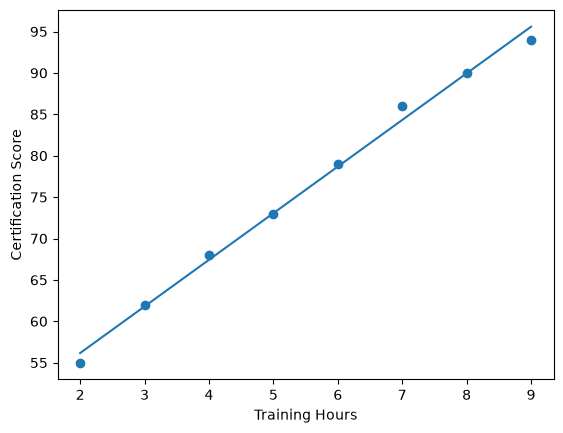

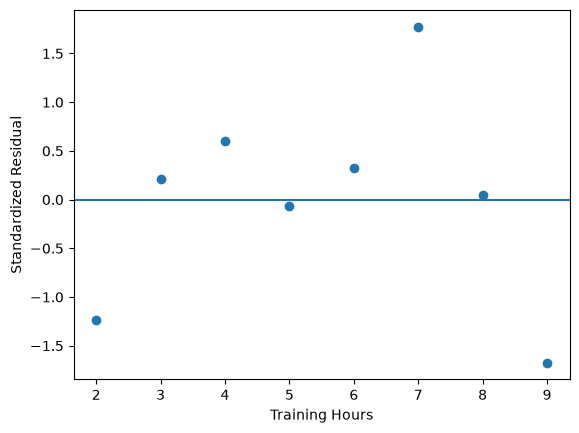

In [50]:
df, A, B, SSR, R2 = regression_analysis()

#print(df)

print("A =", A)
print("B =", B)
print("SSR =", SSR)
print("R² =", R2)

plt.scatter(df['Training Hours'], df['Certification Score'])
plt.plot(df['Training Hours'], df['Predicted Score'])
plt.xlabel("Training Hours")
plt.ylabel("Certification Score")
plt.show()

plt.scatter(df['Training Hours'], df['Standardized Residual'])
plt.axhline(0)
plt.xlabel("Training Hours")
plt.ylabel("Standardized Residual")
plt.show()

### Question: Checking Normality of Regression Errors Using a QQ Plot

You are given the following data:

```python
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import probplot

np.random.seed(42)

x = np.linspace(0, 10, 50)
y = 3*x + 5 + np.random.normal(0, 2, 50)
```

1. Fit a linear regression model to `x` and `y` using `np.polyfit()`.

2. Calculate the predicted values $\hat{y}$ using the fitted model.

3. Calculate the residuals:
   $$
   e_i = y_i - \hat{y}_i
   $$

4. Calculate the standard deviation of the residuals:
   $$
   \sigma = \sqrt{\frac{\sum e_i^2}{n-2}}
   $$

5. Calculate the standardized residuals:
   $$
   e_i^* = \frac{e_i}{\sigma}
   $$

6. Create a **QQ plot** of the standardized residuals using `scipy.stats.probplot()`.

7. Examine the QQ plot and determine whether the regression errors are **approximately normally distributed**.
### Expected Output

- The fitted regression equation.
- A QQ plot of the standardized residuals.
- A conclusion about whether the errors are approximately normally distributed.

Regression equation: y = 3.046x + 4.690


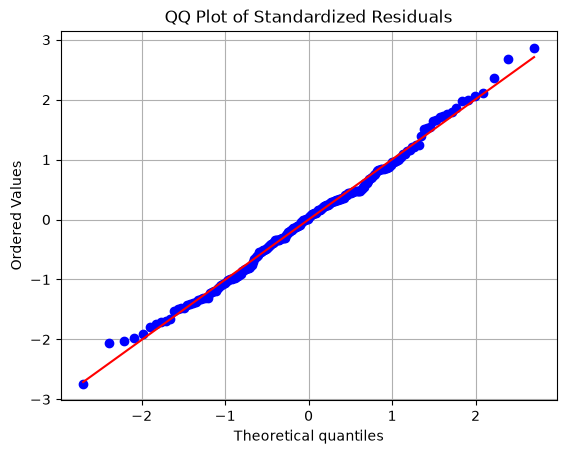

In [51]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import probplot

np.random.seed(42)

n = 200
x = np.linspace(0, 10, n)
y = 3*x + 5 + np.random.normal(0, 2, n)

coef = np.polyfit(x, y, 1)

y_pred = coef[0]*x + coef[1]

residuals = y - y_pred

sigma = np.sqrt(np.sum(residuals**2) / (n - 2))

std_res = residuals / sigma

print(f"Regression equation: y = {coef[0]:.3f}x + {coef[1]:.3f}")

probplot(std_res, plot=plt)
plt.title("QQ Plot of Standardized Residuals")
plt.grid()
plt.show()

### Question: Predicting House Prices Using Linear Regression

A real-estate company wants to predict the price of a house based on its **area**.

```python
import numpy as np

np.random.seed(42)

area = np.random.randint(500, 3001, 100)
noise = np.random.normal(0, 8, 100)
price = 0.05 * area + 10 + noise
```


Using **linear regression**, build a model that predicts the house price from its area.


Complete the code to:

1. Use area as the **input feature (X)** and price as the **target (y)**.
2. Fit a Linear Regression model.
3. Obtain **predicted prices** for the given data.
4. Calculate the **Mean Squared Error (MSE)** of the model.
5. Plot the original data points along with the fitted regression line.
6. Display the **slope** and **intercept** learned by the model.
7. Predict the price of a house with an area of **1600 sq ft**.

Slope: 0.05005478486116573
Intercept: 9.778249710594253
Mean Squared Error: 57.61335169142899
Predicted price for 1600 sq ft: 89.86590548845942 lakhs


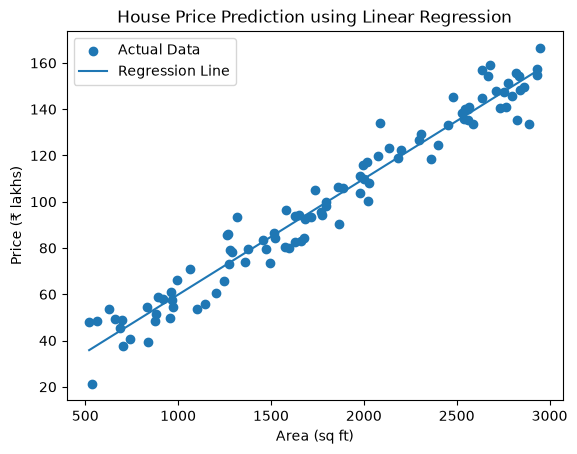

In [52]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

np.random.seed(42)


area = np.random.randint(500, 3001, 100)
noise = np.random.normal(0, 8, 100)
price = 0.05 * area + 10 + noise


X = area.reshape(-1, 1)
y = price

model = LinearRegression()
model.fit(X, y)
y_pred = model.predict(X)


mse = mean_squared_error(y, y_pred)

print("Slope:", model.coef_[0])
print("Intercept:", model.intercept_)
print("Mean Squared Error:", mse)

# Predict price for 1600 sq ft
new_area = np.array([[1600]])
predicted_price = model.predict(new_area)

print("Predicted price for 1600 sq ft:", predicted_price[0], "lakhs")

# Plot data and regression line
plt.scatter(area, price, label="Actual Data")

x_line = np.linspace(area.min(), area.max(), 100).reshape(-1, 1)
y_line = model.predict(x_line)

plt.plot(x_line, y_line, label="Regression Line")

plt.xlabel("Area (sq ft)")
plt.ylabel("Price (₹ lakhs)")
plt.title("House Price Prediction using Linear Regression")
plt.legend()
plt.show()

### Question: Predicting Fuel Efficiency Using Linear Regression

A car manufacturer wants to study the relationship between a car's **weight** and its **fuel efficiency**.

Use the following dictionary to create a Pandas DataFrame:

```python
data = {
    "Weight": [
        1500, 1600, 1700, 1800, 1900, 2000, 2100, 2200, 2300, 2400,
        2500, 2600, 2700, 2800, 2900, 3000, 3100, 3200, 3300, 3400,
        3500, 3600, 3700, 3800, 3900, 4000, 4100, 4200, 4300, 4400
    ],
    
    "Engine_Size": [
        1.2, 1.3, 1.4, 1.5, 1.6, 1.7, 1.8, 1.9, 2.0, 2.1,
        2.2, 2.3, 2.4, 2.5, 2.6, 2.7, 2.8, 2.9, 3.0, 3.1,
        3.2, 3.3, 3.4, 3.5, 3.6, 3.7, 3.8, 3.9, 4.0, 4.1
    ],
    
    "MPG": [
        38, 37, 36, 35, 34, 33, 32, 31, 30, 29,
        29, 28, 27, 27, 26, 25, 25, 24, 23, 23,
        22, 22, 21, 20, 20, 19, 19, 18, 17, 17
    ]
}

```





1. Use `Weight` as the input feature (`X`) and `MPG` as the target (`y`).

2. Split the data into **80% training** and **20% testing** data using `train_test_split()`.

3. Fit a **Simple Linear Regression** model using the training data.

4. Predict the MPG for the test data.

5. Calculate the **Mean Squared Error (MSE)**.

6. Display the **slope and intercept** learned by the model.

7. Predict the MPG of a car weighing **2500 kg**.


For the Spliting of the dataset, use train_test_split from sklearn.model_selection
```python
   from sklearn.model_selection import train_test_split

   # Splits X and y into training and testing sets.
   # test_size=0.2 means 20% of the data is used for testing
   # and the remaining 80% is used for training.

   X_train, X_test, y_train, y_test = train_test_split(
       X, y, test_size=0.2, random_state=42
   )
```



In [54]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

data = {
    "Weight": [
        1500, 1600, 1700, 1800, 1900, 2000, 2100, 2200, 2300, 2400,
        2500, 2600, 2700, 2800, 2900, 3000, 3100, 3200, 3300, 3400,
        3500, 3600, 3700, 3800, 3900, 4000, 4100, 4200, 4300, 4400
    ],
    "Engine_Size": [
        1.2, 1.3, 1.4, 1.5, 1.6, 1.7, 1.8, 1.9, 2.0, 2.1,
        2.2, 2.3, 2.4, 2.5, 2.6, 2.7, 2.8, 2.9, 3.0, 3.1,
        3.2, 3.3, 3.4, 3.5, 3.6, 3.7, 3.8, 3.9, 4.0, 4.1
    ],
    "MPG": [
        38, 37, 36, 35, 34, 33, 32, 31, 30, 29,
        28, 27, 26, 25, 24, 23, 22, 22, 21, 20,
        20, 19, 19, 18, 18, 17, 17, 17, 17, 17
    ]
}

df = pd.DataFrame(data)

X = df[["Weight"]]
y = df["MPG"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)

print("Predicted MPG:")
print(y_pred)

print("MSE:", mse)

print("Slope:", model.coef_[0])
print("Intercept:", model.intercept_)

prediction = model.predict([[2500]])
#prediction = model.predict(pd.DataFrame([[2500]], columns=["Weight"]))

print("Predicted MPG for 2500 kg:", prediction[0])


Predicted MPG:
[15.37155291 24.75935022 18.50081868 23.19471734 30.23556532 29.45324888]
MSE: 1.2810412613279507
Slope: -0.007823164426059981
Intercept: 48.228843502240615
Predicted MPG for 2500 kg: 28.670932437090663


D:\Newfolder\envs\myenv\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


### Question: Predicting Crop Yield Using Polynomial Regression

A farmer wants to study the relationship between the **amount of fertilizer used** and the **crop yield**. The relationship is nonlinear because increasing fertilizer initially improves yield, but the improvement slows down at higher amounts.

Use the following code to generate synthetic data:

```python
import numpy as np

np.random.seed(42)

fertilizer = np.linspace(10, 100, 100)
noise = np.random.normal(0, 2, 100)

yield_amount = (
    -0.01 * fertilizer**2
    + 1.8 * fertilizer
    + 20
    + noise
)
```

Using **Polynomial Regression**, build a model to predict crop yield.

1. Create `X` using `fertilizer` and `y` using `yield_amount`.

2. Split the data into **80% training** and **20% testing** data using `train_test_split()`.

3. Transform the input feature into polynomial features of **degree 2** using `PolynomialFeatures`.

4. Fit a Linear Regression model using the polynomial features.

5. Predict the crop yield for the test data.

6. Calculate the **Mean Squared Error (MSE)** and **$R^2$ score** on the test data.

7. Plot the original data points along with the fitted polynomial regression curve.

8. Predict the crop yield when **50 kg of fertilizer** is used.


MSE: 2.4785321801580564
R²: 0.9942248722562085


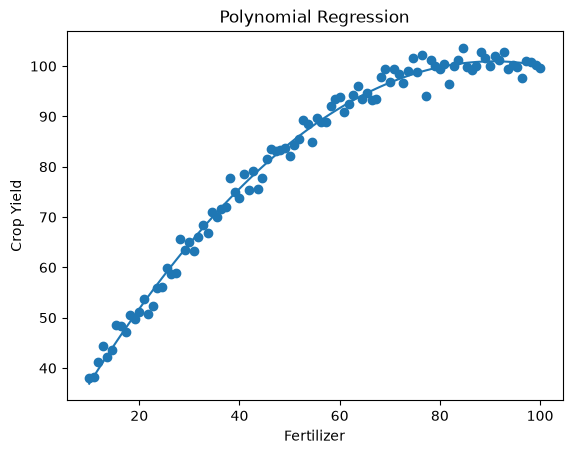

Predicted crop yield for 50 kg fertilizer: 84.62856514035798


In [55]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

np.random.seed(42)

fertilizer = np.linspace(10, 100, 100)
noise = np.random.normal(0, 2, 100)

yield_amount = (
    -0.01 * fertilizer**2
    + 1.8 * fertilizer
    + 20
    + noise
)

X = fertilizer.reshape(-1, 1)
y = yield_amount

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

poly = PolynomialFeatures(degree=2)

X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

model = LinearRegression()
model.fit(X_train_poly, y_train)

y_pred = model.predict(X_test_poly)

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("MSE:", mse)
print("R²:", r2)

X_curve = np.linspace(10, 100, 100).reshape(-1, 1)
X_curve_poly = poly.transform(X_curve)
y_curve = model.predict(X_curve_poly)

plt.scatter(fertilizer, yield_amount)
plt.plot(X_curve, y_curve)
plt.xlabel("Fertilizer")
plt.ylabel("Crop Yield")
plt.title("Polynomial Regression")
plt.show()

fertilizer_50 = poly.transform([[50]])
prediction = model.predict(fertilizer_50)

print("Predicted crop yield for 50 kg fertilizer:", prediction[0])

### Question: Predicting Employee Salary Using Multiple Linear Regression

A company wants to predict an employee's **annual salary** based on their years of experience, number of projects completed, and weekly working hours.

Use the following code to generate a synthetic dataset:

```python
import numpy as np

np.random.seed(42)

experience = np.random.randint(1, 16, 200)
projects = np.random.randint(1, 21, 200)
hours_per_week = np.random.randint(30, 61, 200)

noise = np.random.normal(0, 5000, 200)

salary = (
    40000
    + 5000 * experience
    + 1500 * projects
    + 800 * hours_per_week
    + noise
)
```

Using **Multiple Linear Regression**, build a model to predict the employee's salary.


1. Create the feature matrix `X` using `experience`, `projects`, and `hours_per_week`, and use `salary` as the target `y`.

2. Split the dataset into **80% training** and **20% testing** data.

3. Fit a Multiple Linear Regression model using the training data.

4. Predict salaries for the test data.

5. Calculate the **MSE, RMSE, and $R^2$ score** on the test data.

6. Display the **coefficients and intercept** learned by the model.

7. Predict the salary of an employee with:
   - 7 years of experience
   - 12 projects completed
   - 45 working hours per week

In [57]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, root_mean_squared_error, r2_score

np.random.seed(42)

experience = np.random.randint(1, 16, 200)
projects = np.random.randint(1, 21, 200)
hours_per_week = np.random.randint(30, 61, 200)
noise = np.random.normal(0, 5000, 200)

salary = (
    40000
    + 5000 * experience
    + 1500 * projects
    + 800 * hours_per_week
    + noise
)

X = np.column_stack((experience, projects, hours_per_week))
y = salary

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
rmse = root_mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("MSE:", mse)
print("RMSE:", rmse)
print("R²:", r2)

print("Coefficients:", model.coef_)
print("Intercept:", model.intercept_)

employee = [[7, 12, 45]]
prediction = model.predict(employee)

print("Predicted salary:", prediction[0])

MSE: 20910143.439031046
RMSE: 4572.761030168868
R²: 0.9698372390274399
Coefficients: [4917.61607278 1515.26736574  775.43170841]
Intercept: 41729.43225903952
Predicted salary: 129230.38003564886
